# Introduction to LoKI

LoKI is a **small-angle neutron scattering** (SANS) instrument of the European Spallation Source (ESS). It measures
the size and the shape of objects of 1 to 100 nm: nanoparticles, proteins, polymers, the pores of a membrane. These
objects are far too small for a microscope picture of a whole sample, and LoKI does not take a picture: it measures
how the sample **deflects** neutrons. This page explains how, before you measure with it. No code, nothing to compute
by hand: read, try the pictures, answer the questions. About 40 minutes.

**What you will know at the end**
1. why small angles tell large sizes;
2. what the scattering vector $Q$ is;
3. the parts of LoKI, from the source to the detectors;
4. what the collimation and the detector distance change;
5. how LoKI knows the wavelength of each neutron;
6. which exercises of the catalogue use which capability.

In [ ]:
import sys, os, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.abspath(".."))
import quiz, intro_widgets as iw
q = quiz.Quiz("loki_intro")

## 1. Small angles, large objects

Send a thin beam of neutrons through a liquid that holds nanoparticles. Most neutrons go straight on. A few are
deflected by a small angle, written $2\theta$, and land on the detector a little away from the beam axis. The key
fact, true for every wave: **the larger the object, the smaller the angle** by which it deflects. Objects of a few
nanometers deflect neutrons by a few degrees; objects of 100 nm by a few tenths of a degree only. Measuring *how many*
neutrons go to *which* angle therefore tells the size of the objects.

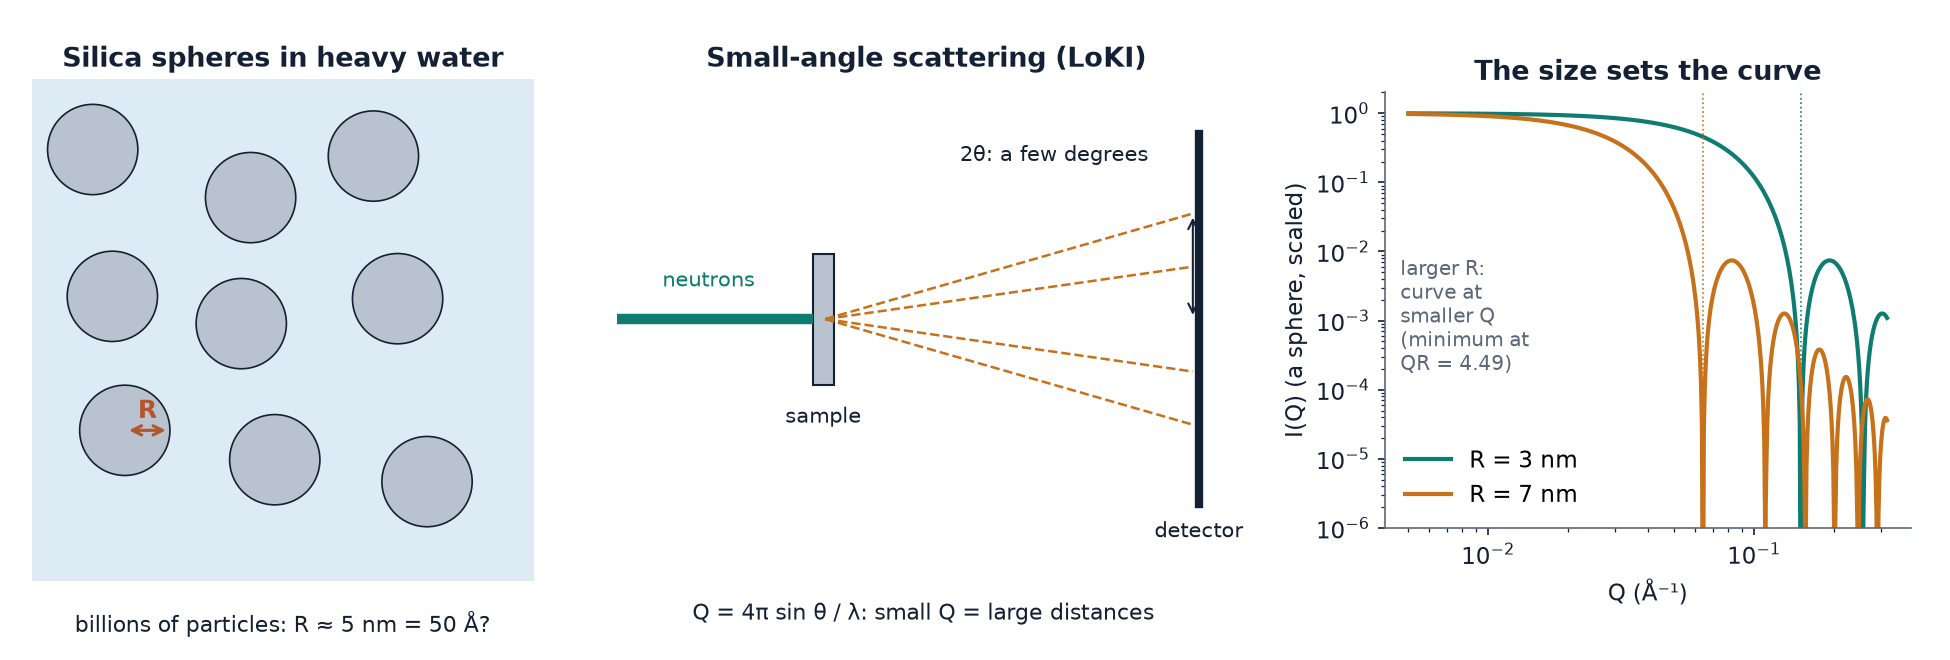

*Left: nanoparticles in a liquid. Middle: they deflect a few neutrons by small angles. Right: the curve of the scattered intensity against Q moves to smaller Q when the particles are larger.*

In [ ]:
q.choice("Two samples hold spheres of 3 nm and of 30 nm. Which one sends its neutrons closest to the beam axis?",
         ["The 30 nm spheres: larger objects deflect by smaller angles.",
          "The 3 nm spheres: smaller objects deflect less.",
          "Both the same: the angle depends only on the neutrons.",
          "Neither deflects neutrons: only crystals do."],
         answer=0, why={1: "The other way round: a small object deflects by a large angle.",
                        2: "The angle depends on the size of the object (and on the wavelength, part 2).",
                        3: "Any object that differs from its surroundings deflects waves; crystals give sharp peaks at "
                           "larger angles."},
         explanation="Size and angle go opposite ways. This is why an instrument for large objects (1 to 100 nm) must "
                     "measure very small angles, and is long.", hints=["Look at the right panel of the figure."],
         title="Q1. Which sample?")

## 2. The scattering vector Q

The angle alone is not enough: a neutron of long wavelength $\lambda$ is deflected more than one of short wavelength
by the same object. Angle and wavelength are combined in one number, the **scattering vector**
$$Q = \frac{4\pi \sin\theta}{\lambda},$$
in Å⁻¹ (1 Å = 0.1 nm), where $2\theta$ is the angle of deflection. An object of size $d$ scatters mostly around
$$Q \approx \frac{2\pi}{d}.$$
All LoKI results are curves of the scattered intensity against $Q$, written $I(Q)$: **small $Q$ = large objects**.

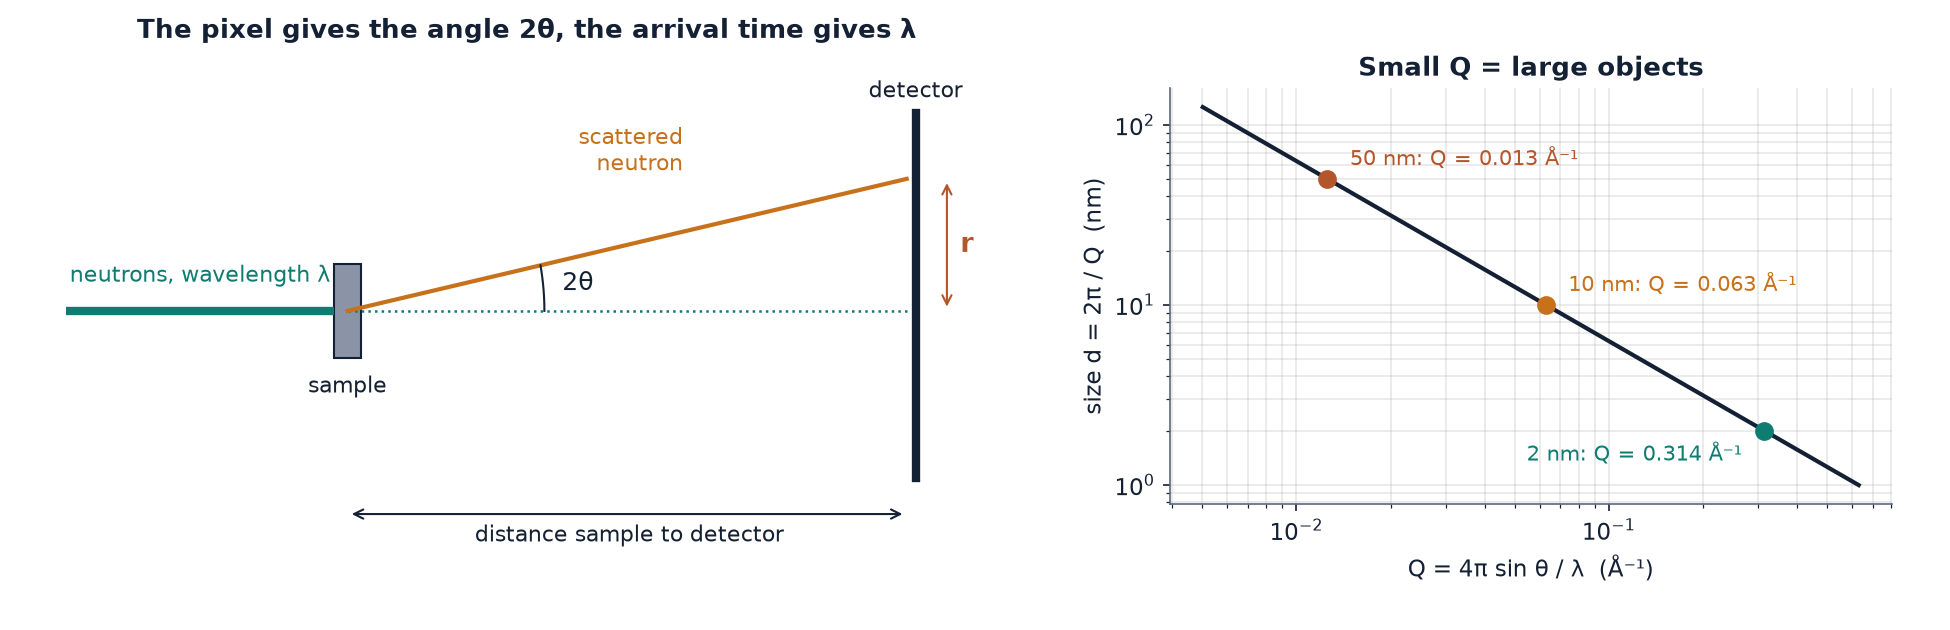

*Left: the pixel hit by the neutron gives the angle 2θ. Right: the size that corresponds to each Q.*

Try it: move the place where the neutron lands, its wavelength, and the distance of the detector.

In [ ]:
iw.loki_q()

In [ ]:
q.number("Around which Q do objects of 10 nm (100 Å) scatter? Use Q ≈ 2π / d.", value=0.063, tol=0.004, unit="Å⁻¹",
         mistakes=[(0.628, "you used d = 10 (nm): Q is in Å⁻¹, so d must be in Å (100 Å)"),
                   (0.01, "1/d; do not forget the factor 2π")],
         hints=["d = 100 Å.", "2 × 3.14 / 100."],
         explanation="2π / 100 Å = 0.063 Å⁻¹. LoKI covers about 0.01 to 0.5 Å⁻¹ in one setting: sizes from about "
                     "60 nm down to 1 nm.", title="Q2. From a size to Q")
q.choice("With the picture above: the neutron lands 10 cm from the axis on the detector at 5 m. You then move the "
         "detector to 10 m and look at the neutrons landing at the same 10 cm. What happens to Q?",
         ["Q is halved: the same place is seen under half the angle, so larger objects are measured.",
          "Q doubles.", "Q does not change: it depends only on the sample.", "Q is divided by 4."],
         answer=0, why={1: "A detector twice as far sees the same 10 cm under half the angle: Q decreases.",
                        2: "Q of a pixel depends on where the pixel is: it changes with the distance.",
                        3: "For small angles Q is proportional to the angle, which is halved, not divided by 4."},
         explanation="For small angles 2θ ≈ r / distance: twice the distance, half the angle, half the Q. Moving the "
                     "detector away is how a SANS instrument reaches smaller Q, that is larger objects.",
         hints=["Try it with the buttons 5 m and 10 m."], title="Q3. Moving the detector")

## 3. LoKI, from the source to the detectors

ESS makes neutrons in **pulses**: 14 times per second, for 2.86 ms. On LoKI the sample is 23.5 m from the source:

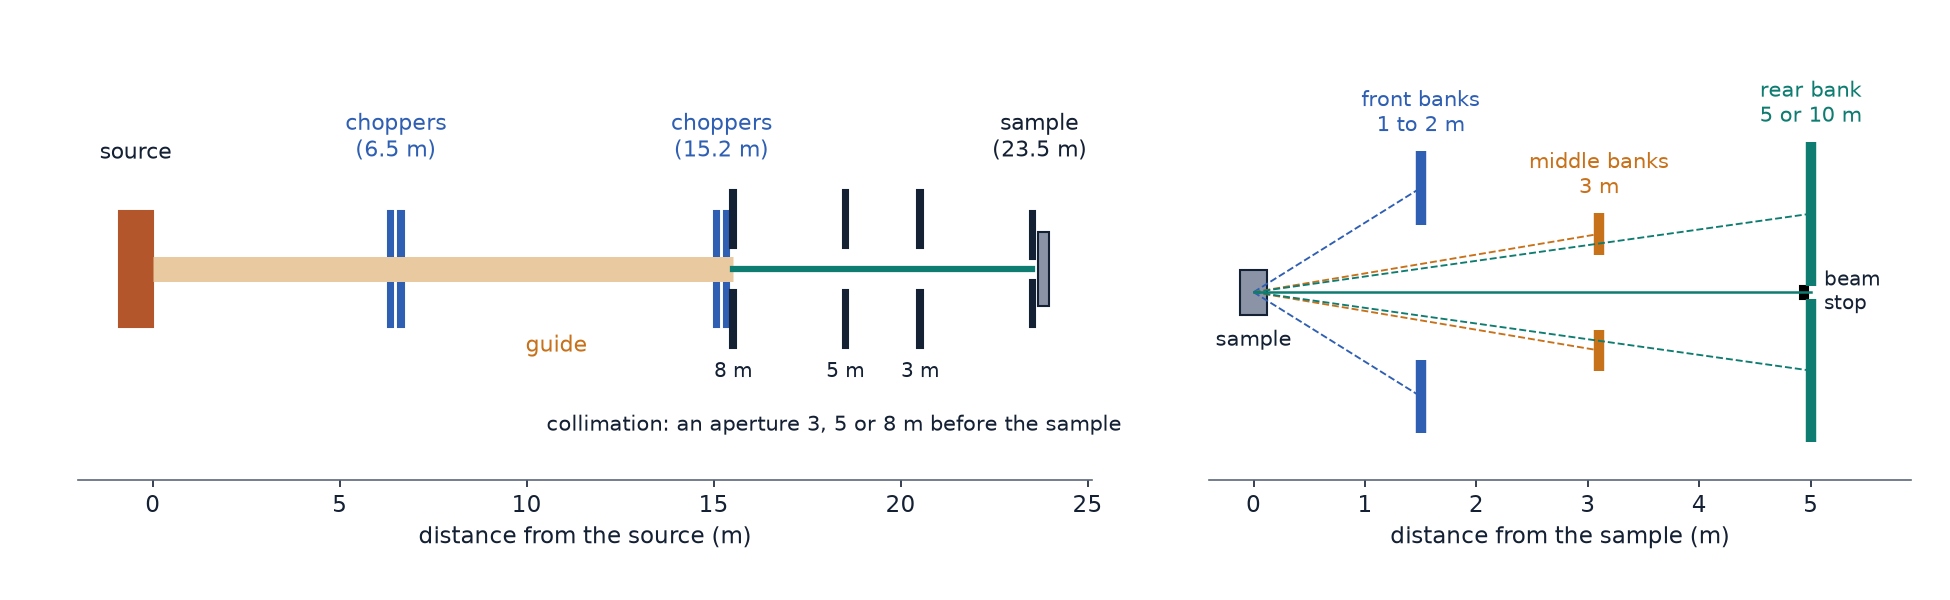

*LoKI (distances of its official McStas model). Left: from the source to the sample. Right: from the sample to the three groups of detector banks.*

- two pairs of **choppers** (rotating discs with an opening) choose the band of wavelengths (part 5);
- the **collimation** makes the beam thin and parallel: two apertures, one just before the sample (1 cm), one 3, 5 or
  8 m before it (part 4);
- the **sample** is a liquid in a flat cell 1 mm thick, or a solid sheet;
- **nine detector banks** surround the beam: a **rear bank** on a carriage 5 or 10 m behind the sample for the
  smallest angles, **middle banks** at 3 m and **front banks** at 1 to 2 m for the larger angles. A small absorber,
  the **beam stop**, protects the rear bank from the neutrons that went straight on.

Why three groups? To cover a wide range of $Q$, hence of sizes, in **one** measurement.

In [ ]:
q.choice("A sample contains small objects of 2 nm. Which detector banks see most of their scattering?",
         ["The front banks: small objects scatter to large angles.",
          "The rear bank: it is the largest.",
          "The beam stop.",
          "All the same: the scattering does not depend on the angle."],
         answer=0, why={1: "The rear bank, far behind the sample, covers the smallest angles: large objects.",
                        2: "The beam stop absorbs the neutrons that were not deflected; it measures nothing.",
                        3: "The whole method rests on the scattering depending on the angle."},
         explanation="2 nm = 20 Å scatters around Q = 2π/20 = 0.31 Å⁻¹: large angles, the front banks.",
         hints=["Small objects: small or large angles?"], title="Q4. Which banks?")

## 4. Collimation: parallel or bright?

To measure a deflection of a fraction of a degree, the neutrons must all arrive from almost the same direction:
the beam must be **parallel**. The collimation does this with two apertures: the farther apart they are, the fewer
directions pass both. But fewer directions also means **fewer neutrons**. The values below were measured on the
beams of the twin (official McStas model of LoKI):

In [ ]:
iw.loki_collimation()

A more parallel beam gives a sharper measurement of the angle, hence of $Q$: fine details of the curve $I(Q)$ are
kept. A less parallel beam smooths them, but the measurement is faster. As on a camera (sharp or bright), there is no
best setting: it depends on the sample.

To reach the **smallest $Q$** (the largest objects), the rear bank is moved from 5 to 10 m (question Q3). In the
twin this goes with the 8 m collimation (part 5 says why).

In [ ]:
q.number("From the picture above: how many times fewer neutrons per second reach the sample with the 8 m collimation "
         "than with the 3 m one?", value=12, tol=1.5, unit="times",
         mistakes=[(3.7, "that is how much more parallel the beam is; look at the left panel"),
                   (2.7, "the ratio of the lengths (8 / 3); look at the measured values")],
         hints=["Click 8 m and read the sentence under the picture.", "9.4 / 0.78."],
         explanation="9.4·10⁸ / 7.8·10⁷ ≈ 12 times fewer neutrons, for a beam 3.7 times more parallel. For the same "
                     "noise you would count 12 times longer.", title="Q5. The price of a parallel beam")

## 5. Time of flight: a whole band of wavelengths at once

A neutron is also a wave, and its **wavelength** depends only on its speed: $\lambda\,[\text{Å}] = 3956 / v\,[\text{m/s}]$.
Slow neutrons have a long wavelength. LoKI uses neutrons from **3 to 11.5 Å** at the same time. This is a great
advantage: one pixel of the detector sees one angle but many wavelengths, hence many values of $Q$ at once.

But $Q$ needs the wavelength of each neutron. LoKI gets it from the **arrival time**: all neutrons of a pulse leave
together, and the slow ones arrive later. To the rear bank at 5 m (28.5 m from the source), a 3 Å neutron needs
22 ms and an 11.5 Å neutron 83 ms.

The pulses come every 71.4 ms, so the slowest neutrons of one pulse must not be caught up by the fastest of the next:
the difference between their arrival times must stay below 71.4 ms. This is the job of the **choppers**: they let
through only the chosen band.

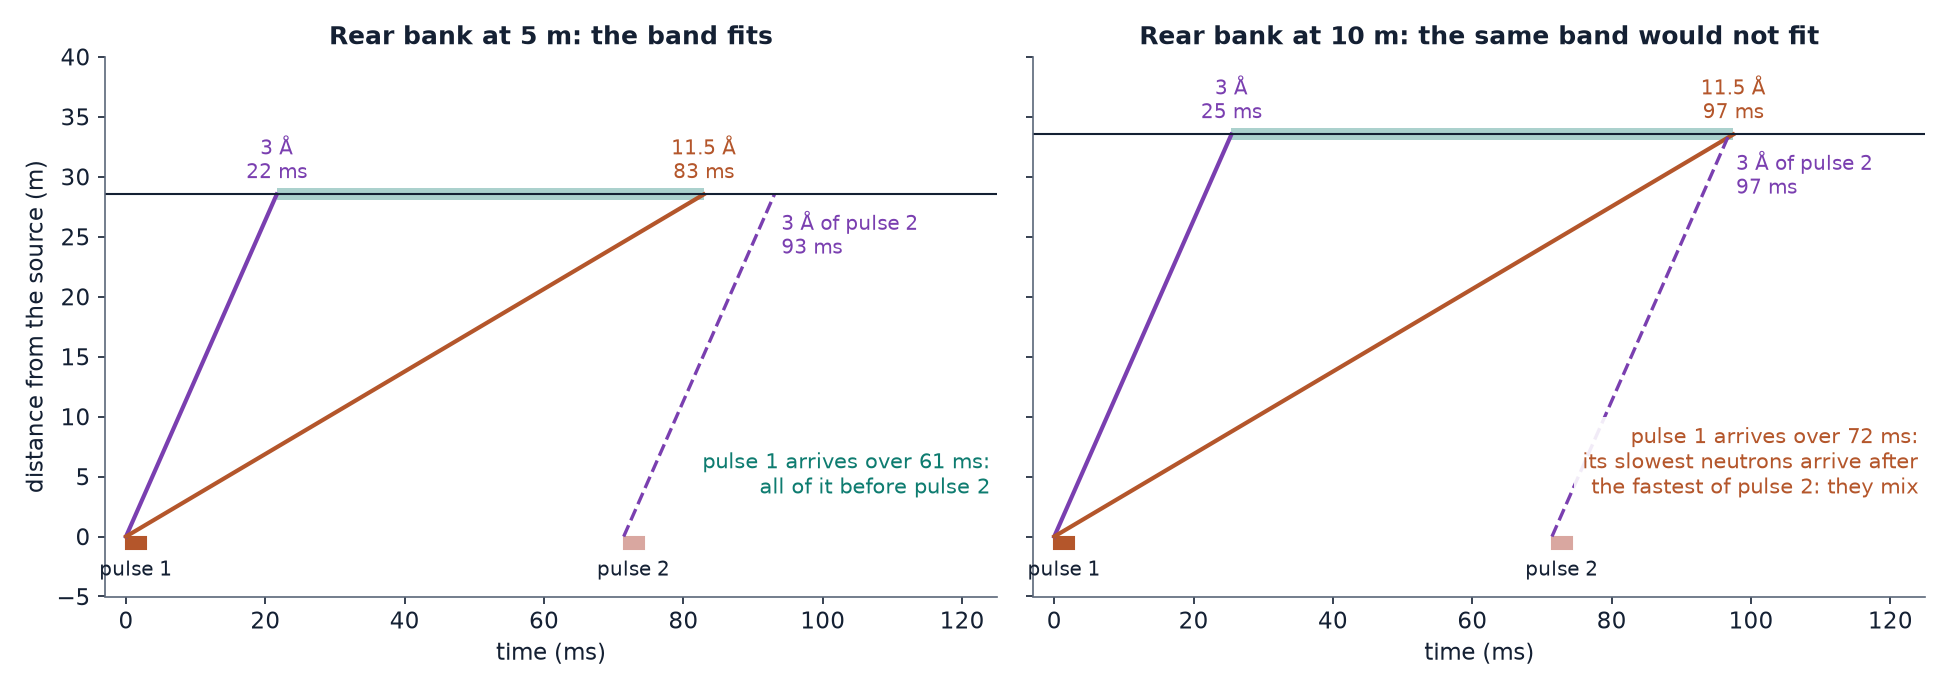

*Distance against time on LoKI. Left: with the rear bank at 5 m, the band 3 to 11.5 Å of a pulse arrives before the fastest neutrons of the next pulse. Right: at 10 m the flight is longer and the same band would mix with the next pulse.*

In [ ]:
q.number("A 3 Å neutron reaches the rear bank after 22 ms, an 11.5 Å neutron after 83 ms. How long after the first "
         "does the last neutron of a pulse arrive?", value=61, tol=1.5, unit="ms",
         mistakes=[(105, "you added the two times; the question is the difference"),
                   (71.4, "the time between two pulses; here: 83 − 22")],
         hints=["83 − 22."],
         explanation="61 ms, less than the 71.4 ms between two pulses: the neutrons of two pulses never mix. With the "
                     "rear bank at 10 m the flight is longer and the same band would take 72 ms: too much. This is why "
                     "the twin, like the instrument, then asks for the 8 m collimation, whose band is narrower "
                     "(3 to 10 Å).", title="Q6. Does the band fit between two pulses?")

## 6. A measurement on LoKI, and what it is used for

A SANS result needs **three measurements** in the same setting: the **sample** (the objects in their liquid), the
**solvent** alone (its own scattering is subtracted), and the **empty beam** (how many neutrons arrive, to know which
fraction crosses the sample). The ESS software then gives $I(Q)$ in absolute units, and a model fitted to the curve
gives sizes and amounts. The catalogue of the app has, or will have, an exercise for each use:

| What you look at | What it tells | Typical question | In the catalogue |
|---|---|---|---|
| $I(Q)$ of particles in a liquid | their size, shape and amount | Is this batch of nanoparticles the right size? | **How big are these nanoparticles?** |
| The same with other mixtures of water and heavy water (**contrast variation**) | which part of a composite object is where | Where is the polymer shell around this particle? | *Small structures in a membrane* (planned) |
| A peak in $I(Q)$ | a distance that repeats | How far apart are the water channels of a fuel-cell membrane? | planned |
| The slope of $I(Q)$ at large $Q$ | the surface of the pores | How porous is this electrode? | planned |
| A sample that changes (temperature, time) | how a structure forms or ages | How does this gel form? | planned |

Start with **How big are these nanoparticles?**: you will choose the collimation and the detector distance, measure
silica spheres in heavy water, and read their radius from $I(Q)$.

In [ ]:
q.choice("Why does a SANS measurement of particles in a liquid also need a measurement of the liquid alone?",
         ["The liquid and the cell scatter neutrons too: this is subtracted to keep the scattering of the particles.",
          "To clean the instrument between two samples.",
          "To measure the wavelength of the neutrons.",
          "It is not needed if the count is long enough."],
         answer=0, why={1: "Nothing is cleaned: it is a measurement, analyzed with the others.",
                        2: "The wavelength comes from the arrival time of each neutron (part 5).",
                        3: "Counting longer reduces the noise, not the scattering of the liquid: the curve would stay "
                           "wrong by the same amount."},
         explanation="I(Q) of the particles = sample − solvent, each divided by the number of neutrons sent. The empty "
                     "beam gives the fraction of neutrons that crosses each of them.",
         hints=["What else than the particles is in the beam?"], title="Q7. Why the solvent?")
q.choice("You want to measure the large pores (60 nm) of an electrode. Which setting do you choose?",
         ["Rear bank at 10 m with the 8 m collimation: the smallest Q, and you count longer.",
          "Rear bank at 5 m with the 3 m collimation: the most neutrons.",
          "Only the front banks.",
          "Any: all settings cover all sizes."],
         answer=0, why={1: "The most neutrons, but its smallest Q (0.0115 Å⁻¹) is too large for 60 nm objects.",
                        2: "The front banks cover large angles: small objects.",
                        3: "Each setting has a smallest Q, set by the distance of the rear bank."},
         explanation="60 nm = 600 Å scatters around Q = 2π/600 = 0.0105 Å⁻¹. With the rear bank at 5 m the curve starts "
                     "at 0.0115 Å⁻¹; at 10 m it starts at 0.008 Å⁻¹. The "
                     "beam has 12 times fewer neutrons: a longer count.",
         hints=["Large objects: which Q? (Q2)", "What did moving the detector do? (Q3)"], title="Q8. Which setting?")
q.report()

**Next.** Close this tab and open *How big are these nanoparticles?* in the catalogue.